# Biến đổi Fourier của tín hiệu rời rạc

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dangquanghieu/tinhieu-hethong-notebooks/blob/main/notebooks/06_bien-doi-fourier-tin-hieu-roi-rac.ipynb)

Notebook minh họa biến đổi Fourier của tín hiệu rời rạc (discrete-time Fourier transform, DTFT): biểu diễn một dãy bằng các thành phần tần số, quan sát phổ và nối phép chập với phép nhân trong miền tần số. Notebook không dùng DFT hoặc FFT.

## Mục tiêu

- Tính trực tiếp $X(e^{j\omega})$ của một dãy hữu hạn trên lưới tần số liên tục.
- Quan sát tính tuần hoàn $2\pi$ của phổ và ý nghĩa của phổ biên độ, phổ pha.
- Liên hệ độ dài dãy chữ nhật với độ rộng búp chính của phổ.
- Kiểm chứng phép dịch chỉ số chỉ đổi pha phổ.
- Tái tạo gần đúng dãy từ biến đổi Fourier ngược số.
- Kiểm chứng $Y(e^{j\omega})=X(e^{j\omega})H(e^{j\omega})$ cho một hệ LTI.

## Tóm tắt lý thuyết

Với dãy $x[n]$ có tổng tuyệt đối hội tụ, biến đổi Fourier của tín hiệu rời rạc được định nghĩa bởi

$$
X(e^{j\omega}) := \sum_{n=-\infty}^{\infty}x[n]e^{-j\omega n}.
$$

Biến đổi Fourier ngược là

$$
x[n] = \frac{1}{2\pi}\int_{-\pi}^{\pi}X(e^{j\omega})e^{j\omega n}\,d\omega.
$$

Vì $e^{-j(\omega+2\pi)n}=e^{-j\omega n}$ với mọi $n\in\mathbb{Z}$, phổ luôn tuần hoàn:

$$
X(e^{j(\omega+2\pi)})=X(e^{j\omega}).
$$

Nếu hệ LTI có đáp ứng xung $h[n]$, thì

$$
y[n]=x[n]*h[n]
\quad\overset{\operatorname{FT}}{\longleftrightarrow}\quad
Y(e^{j\omega})=X(e^{j\omega})H(e^{j\omega}).
$$

Đây là mở rộng trực tiếp của kết quả ở notebook trước: từng thành phần $e^{j\omega n}$ được nhân với trị riêng $H(e^{j\omega})$.

**Xem thêm:** Chương 3, *Biến đổi Fourier*; các mục về biến đổi Fourier của tín hiệu rời rạc, các tính chất của biến đổi và đáp ứng tần số trong [giáo trình](https://github.com/dangquanghieu/book-thht).

## Bản đồ Python của notebook

Sinh viên chỉ cần chạy và đọc mã. `omega` là mảng các giá trị tần số rời rạc theo nghĩa biến liên tục, đơn vị rad/mẫu; nó không phải chỉ số DFT.

| Ý tưởng Python | Vai trò trong minh họa | Liên hệ với tín hiệu |
|---|---|---|
| `np.exp(-1j * n[:, None] * omega)` | tạo các hạt nhân Fourier | $e^{-j\omega n}$ trên mọi cặp $(n,\omega)$ |
| broadcasting và `axis=0` | tính tổng theo chỉ số $n$ | định nghĩa của $X(e^{j\omega})$ |
| `np.trapezoid` | xấp xỉ tích phân ngược | tổng Riemann của biến đổi Fourier ngược |
| `np.convolve` và `np.allclose` | kiểm chứng chập và phép nhân phổ | $Y(e^{j\omega})=X(e^{j\omega})H(e^{j\omega})$ |
| `plot`, `stem` | vẽ phổ và dãy | miền tần số và miền chỉ số |

### Khởi tạo: chỉ cần chạy

Cell này nạp thư viện, định dạng hình, và định nghĩa các hàm tính/vẽ dùng chung. Không cần phân tích chi tiết mã hạ tầng này.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "lines.linewidth": 2.0,
})


def stem_sequence(ax, n, x, label=None, color="C0"):
    """Draw a discrete-time sequence x[n] on an explicit index axis."""
    markerline, stemlines, _ = ax.stem(n, x, basefmt=" ", label=label)
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.axhline(0, color="0.25", linewidth=0.8)
    ax.set_xlabel("Chỉ số $n$")
    ax.set_ylabel("Biên độ")
    if label is not None:
        ax.legend()


def dtft(x, n, omega):
    """Evaluate the DTFT of finite samples x[n] on a frequency grid."""
    kernel = np.exp(-1j * n[:, None] * omega[None, :])
    return np.sum(x[:, None] * kernel, axis=0)


def plot_spectrum(omega, spectrum, title):
    """Plot magnitude and principal phase of a DTFT over one period."""
    magnitude = np.abs(spectrum)
    phase = np.angle(spectrum)
    phase[magnitude < 0.02 * magnitude.max()] = np.nan

    fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
    axes[0].plot(omega / np.pi, magnitude)
    axes[0].set_ylabel(r"$|X(e^{j\omega})|$")
    axes[0].set_title(title)
    axes[1].plot(omega / np.pi, phase)
    axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
    axes[1].set_ylabel(r"$\arg\{X(e^{j\omega})\}$ (rad)")
    axes[1].set_ylim(-np.pi, np.pi)
    axes[1].set_yticks(
        [-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi],
        [r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"],
    )
    fig.tight_layout()
    plt.show()

## Minh họa 1: Tính tổng DTFT trực tiếp

Ta xét một dãy hữu hạn không đối xứng. Với dãy hữu hạn, tổng định nghĩa DTFT chỉ chạy trên các chỉ số có giá trị khác $0$. Code sẽ tính tổng này tại nhiều giá trị $\omega$ trong một chu kỳ $[-\pi,\pi]$.

**Python cần biết:** Nếu `n` có $N$ phần tử và `omega` có $M$ phần tử, `n[:, None]` có kích thước $(N,1)$. Khi nhân với `omega[None, :]`, NumPy tạo một ma trận $(N,M)$: hàng thứ $i$ chứa $e^{-j\omega n_i}$ trên toàn bộ trục tần số. `np.sum(..., axis=0)` cộng các hàng, tức là thực hiện tổng theo $n$.

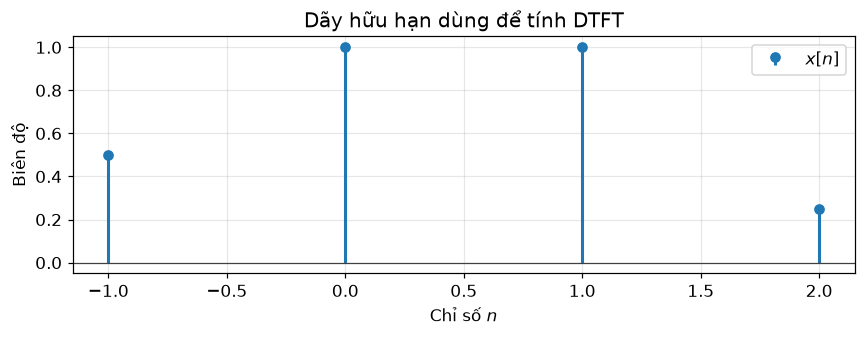

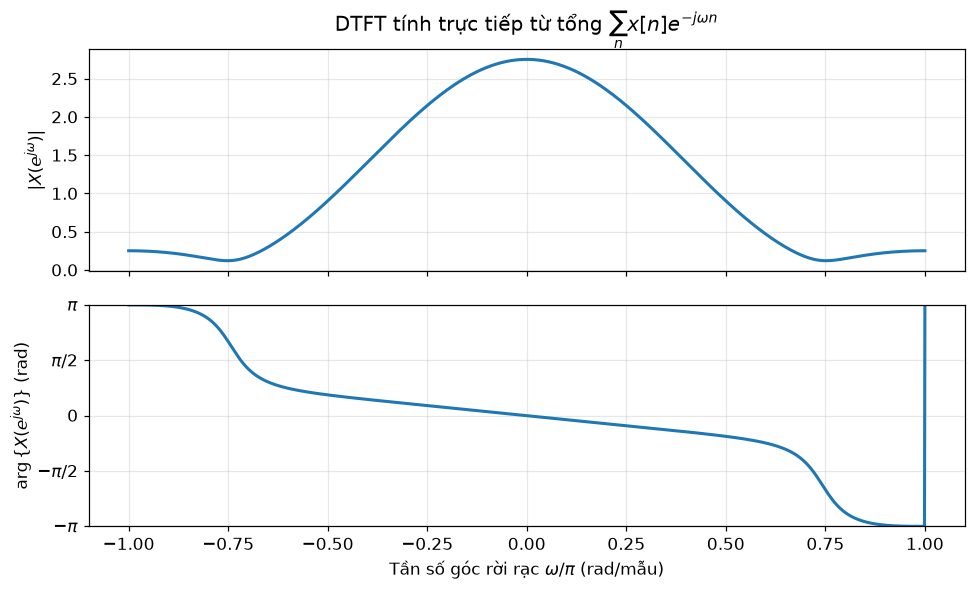

In [2]:
# Tạo một dãy hữu hạn cùng trục chỉ số của nó.
n_x = np.arange(-1, 3)
x = np.array([0.5, 1.0, 1.0, 0.25])
omega = np.linspace(-np.pi, np.pi, 2_001)

# Tính DTFT trực tiếp theo định nghĩa.
X = dtft(x, n_x, omega)

# Vẽ dãy và phổ của dãy.
fig, ax = plt.subplots(figsize=(8, 3.2))
stem_sequence(ax, n_x, x, label=r"$x[n]$", color="C0")
ax.set_title("Dãy hữu hạn dùng để tính DTFT")
fig.tight_layout()
plt.show()

plot_spectrum(omega, X, r"DTFT tính trực tiếp từ tổng $\sum_n x[n]e^{-j\omega n}$")

**Nhận xét:** DTFT là một hàm liên tục theo $\omega$, dù tín hiệu là rời rạc theo $n$. Dãy không đối xứng quanh $n=0$ có phổ pha khác $0$; phổ biên độ một mình không ghi lại đầy đủ vị trí và hình dạng của dãy.

## Minh họa 2: Độ dài dãy chữ nhật và phổ

Xét dãy chữ nhật $x_N[n]=\operatorname{rect}_N[n]$, bằng $1$ từ $n=0$ đến $n=N-1$. Ta thay đổi $N$ và quan sát phổ biên độ trong một chu kỳ. Dãy dài hơn theo chỉ số có búp chính hẹp hơn theo tần số.

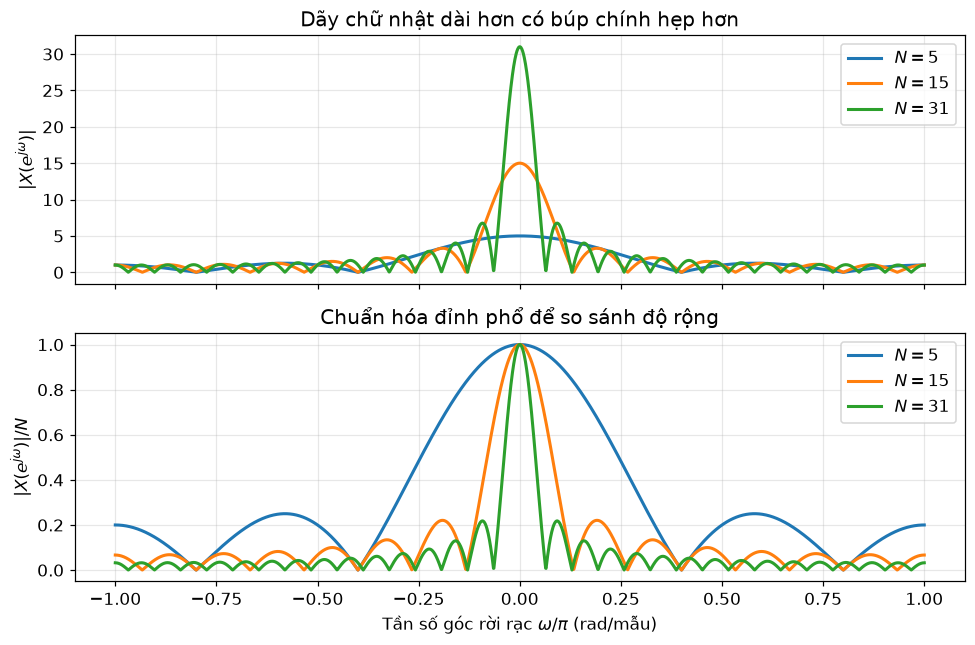

In [3]:
# Tạo ba dãy chữ nhật có độ dài khác nhau.
omega = np.linspace(-np.pi, np.pi, 2_001)
lengths = [5, 15, 31]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for length in lengths:
    n_rect = np.arange(length)
    x_rect = np.ones(length)
    X_rect = dtft(x_rect, n_rect, omega)
    axes[0].plot(omega / np.pi, np.abs(X_rect), label=rf"$N={length}$")
    axes[1].plot(omega / np.pi, np.abs(X_rect) / length, label=rf"$N={length}$")

axes[0].set_ylabel(r"$|X(e^{j\omega})|$")
axes[0].set_title("Dãy chữ nhật dài hơn có búp chính hẹp hơn")
axes[0].legend()
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel(r"$|X(e^{j\omega})|/N$")
axes[1].set_title("Chuẩn hóa đỉnh phổ để so sánh độ rộng")
axes[1].legend()
fig.tight_layout()
plt.show()

**Nhận xét:** Kéo dài dãy chữ nhật làm các đặc trưng phổ tập trung hơn quanh $\omega=0$, nhưng không loại bỏ các búp phụ. Đây là một trực giác quan trọng về đánh đổi giữa độ dài quan sát theo chỉ số và độ phân giải theo tần số.

## Minh họa 3: Phép dịch chỉ số và pha phổ

Với $y[n]=x[n-n_0]$, tính chất dịch chỉ số cho

$$
Y(e^{j\omega})=e^{-j\omega n_0}X(e^{j\omega}).
$$

Vì $|e^{-j\omega n_0}|=1$, phép dịch chỉ số giữ nguyên phổ biên độ và chỉ thay đổi phổ pha. Ta kiểm chứng cả hai vế bằng tính trực tiếp.

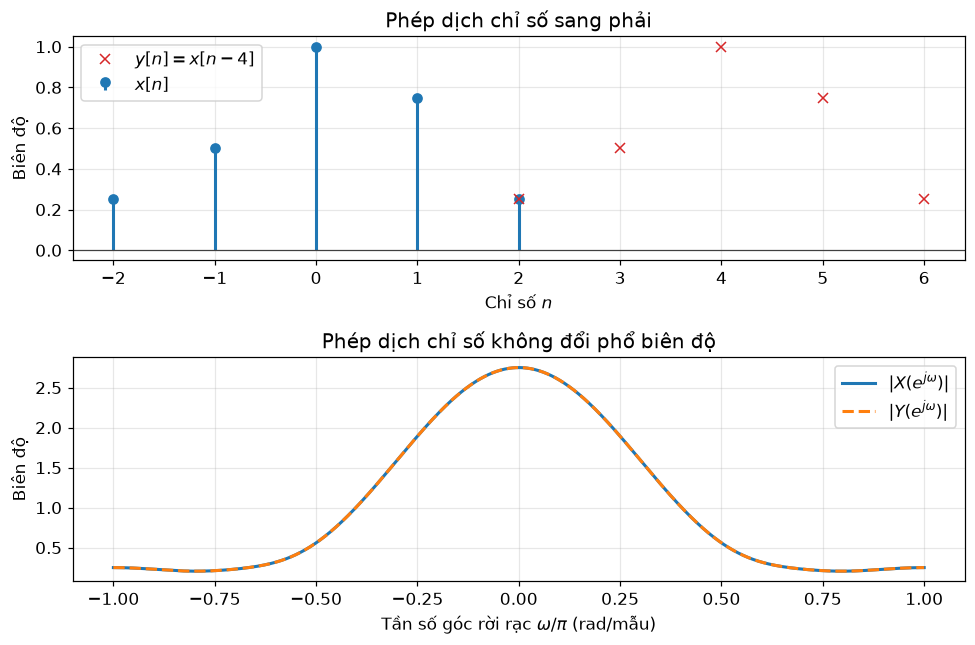

Kiểm chứng Y(e^{jω}) = exp(-jωn₀) X(e^{jω}): True


In [4]:
# Tạo một dãy và phiên bản dịch sang phải n0 mẫu.
n_base = np.arange(-2, 3)
x_base = np.array([0.25, 0.5, 1.0, 0.75, 0.25])
n0 = 4
n_shifted = n_base + n0
y_shifted = x_base.copy()
omega = np.linspace(-np.pi, np.pi, 2_001)

# Tính hai phổ trực tiếp và theo tính chất dịch chỉ số.
X_base = dtft(x_base, n_base, omega)
Y_direct = dtft(y_shifted, n_shifted, omega)
Y_from_shift = np.exp(-1j * omega * n0) * X_base
assert np.allclose(Y_direct, Y_from_shift)

# So sánh dãy, phổ biên độ và sai khác pha dự đoán.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], n_base, x_base, label=r"$x[n]$", color="C0")
axes[0].plot(n_shifted, y_shifted, "x", color="C3", label=rf"$y[n]=x[n-{n0}]$")
axes[0].set_title("Phép dịch chỉ số sang phải")
axes[0].legend()

axes[1].plot(omega / np.pi, np.abs(X_base), label=r"$|X(e^{j\omega})|$")
axes[1].plot(omega / np.pi, np.abs(Y_direct), "--", label=r"$|Y(e^{j\omega})|$")
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel("Biên độ")
axes[1].set_title("Phép dịch chỉ số không đổi phổ biên độ")
axes[1].legend()
fig.tight_layout()
plt.show()

print("Kiểm chứng Y(e^{jω}) = exp(-jωn₀) X(e^{jω}):", np.allclose(Y_direct, Y_from_shift))

**Nhận xét:** Phổ biên độ của hai dãy chồng khít. Nhân với $e^{-j\omega n_0}$ tạo pha tuyến tính theo $\omega$, nên thông tin về vị trí của dãy nằm trong phổ pha chứ không nằm trong phổ biên độ.

## Minh họa 4: Phổ của tổ hợp các thành phần hình sin

Ta quan sát một đoạn hữu hạn của tín hiệu gồm hai thành phần hình sin:

$$
x[n]=\cos(0.25\pi n)+0.5\cos(0.625\pi n), \qquad 0\leq n\leq31.
$$

Hai tần số đều khớp với độ dài quan sát $32$ mẫu. Phổ biên độ sẽ có các cụm đỉnh gần cặp tần số dương và âm tương ứng.

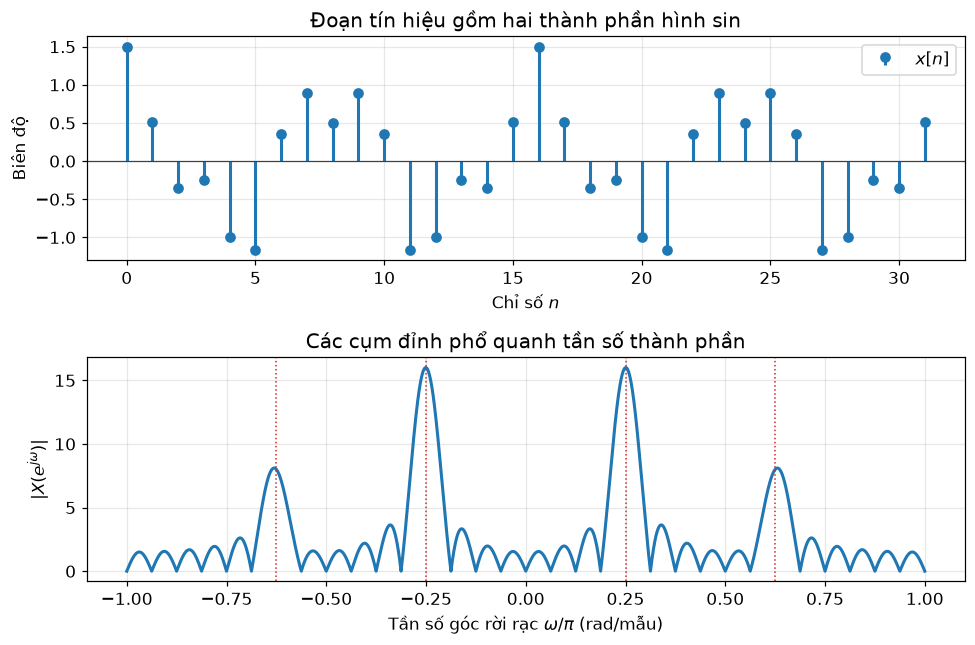

In [5]:
# Tạo đoạn tín hiệu gồm hai thành phần hình sin.
n_mix = np.arange(32)
x_mix = np.cos(0.25 * np.pi * n_mix) + 0.5 * np.cos(0.625 * np.pi * n_mix)
omega = np.linspace(-np.pi, np.pi, 4_001)
X_mix = dtft(x_mix, n_mix, omega)

# Vẽ tín hiệu và phổ biên độ hai phía.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], n_mix, x_mix, label=r"$x[n]$", color="C0")
axes[0].set_title("Đoạn tín hiệu gồm hai thành phần hình sin")

axes[1].plot(omega / np.pi, np.abs(X_mix))
for omega_0 in [-0.625 * np.pi, -0.25 * np.pi, 0.25 * np.pi, 0.625 * np.pi]:
    axes[1].axvline(omega_0 / np.pi, color="C3", linestyle=":", linewidth=1.0)
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel(r"$|X(e^{j\omega})|$")
axes[1].set_title("Các cụm đỉnh phổ quanh tần số thành phần")
fig.tight_layout()
plt.show()

**Nhận xét:** Vì $x[n]$ là thực, phổ biên độ có đối xứng quanh $\omega=0$. Mỗi thành phần hình sin thực tạo đóng góp ở cả tần số dương và âm. Một tín hiệu hình sin kéo dài vô hạn có phổ vạch theo nghĩa biến đổi Fourier mở rộng. Ở đây, code chỉ tạo đoạn dài $32$ mẫu, tương đương nhân tín hiệu đó với một dãy chữ nhật. Phép nhân theo chỉ số làm mỗi vạch được mở rộng thành một búp phổ, nên hình vẽ không gồm các vạch lý tưởng. Nhận xét này chỉ giải thích phạm vi minh họa; cửa sổ hóa và phân tích phổ chi tiết thuộc học phần Xử lý tín hiệu số.

## Minh họa 5: Tái tạo bằng biến đổi Fourier ngược số

Ta dùng DTFT của dãy ở Minh họa 1, rồi xấp xỉ tích phân Fourier ngược bằng quy tắc hình thang trên một lưới tần số dày:

$$
x[n]\approx\frac{1}{2\pi}\sum_m X(e^{j\omega_m})e^{j\omega_m n}\,\Delta\omega.
$$

Ở đây `np.trapezoid` xấp xỉ tích phân theo $\omega$; đây không phải DFT ngược.

**Python cần biết:** `np.trapezoid(values, x=omega, axis=1)` tích phân từng hàng của `values` theo trục `omega`. Mỗi hàng tương ứng một chỉ số $n$, nên kết quả là một mảng các mẫu tái tạo. `np.allclose` kiểm tra hai cách biểu diễn cho cùng một dãy trong sai số số học.

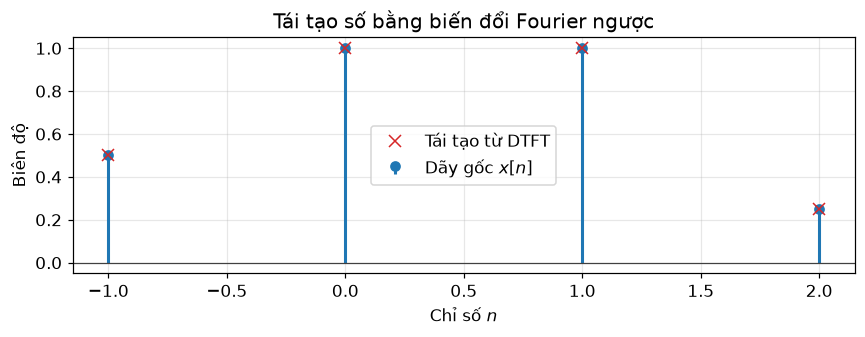

Sai số tái tạo lớn nhất: 2.22e-16


In [6]:
# Dùng lại X(e^{jω}) của dãy ở Minh họa 1 trên lưới dày.
omega_inverse = np.linspace(-np.pi, np.pi, 4_001)
X_inverse = dtft(x, n_x, omega_inverse)

# Xấp xỉ tích phân Fourier ngược cho từng chỉ số n.
kernels_inverse = np.exp(1j * n_x[:, None] * omega_inverse[None, :])
x_reconstructed = np.trapezoid(
    X_inverse[None, :] * kernels_inverse,
    x=omega_inverse,
    axis=1,
) / (2 * np.pi)
assert np.allclose(np.real(x_reconstructed), x, atol=1e-6)

# So sánh dãy gốc và dãy tái tạo.
fig, ax = plt.subplots(figsize=(8, 3.2))
stem_sequence(ax, n_x, x, label=r"Dãy gốc $x[n]$", color="C0")
ax.plot(n_x, np.real(x_reconstructed), "x", color="C3", markersize=8, label="Tái tạo từ DTFT")
ax.set_title("Tái tạo số bằng biến đổi Fourier ngược")
ax.legend()
fig.tight_layout()
plt.show()

maximum_error = np.max(np.abs(x_reconstructed - x))
print(f"Sai số tái tạo lớn nhất: {maximum_error:.2e}")

**Nhận xét:** Tích phân nghịch trên một chu kỳ tái tạo lại dãy ban đầu với sai số số rất nhỏ. Như vậy, $X(e^{j\omega})$ không chỉ là biểu đồ quan sát mà còn là một biểu diễn đầy đủ của dãy khi giữ cả biên độ và pha.

## Minh họa 6: Phép nhân phổ của hệ LTI

Ta đưa tín hiệu hai thành phần ở trên qua bộ lọc trung bình trượt năm mẫu:

$$
h[n]=\frac{1}{5}\operatorname{rect}_5[n].
$$

Theo phép chập trong miền chỉ số và kết quả về hàm riêng của hệ LTI,

$$
y[n]=x[n]*h[n]
\quad\Longleftrightarrow\quad
Y(e^{j\omega})=X(e^{j\omega})H(e^{j\omega}).
$$

Cell dưới đây tính cả hai vế trực tiếp và kiểm chứng đẳng thức số.

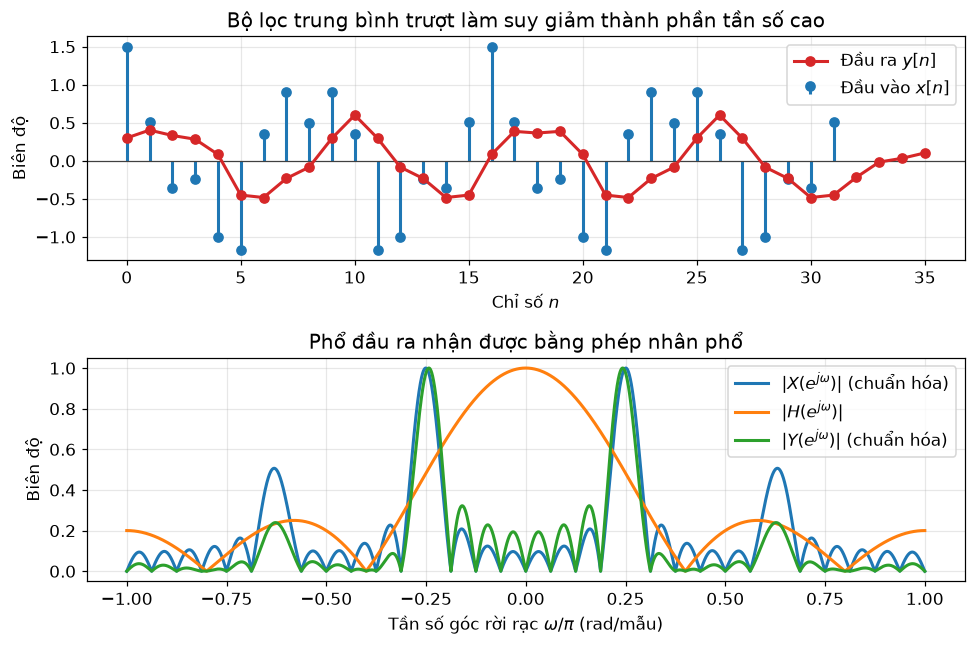

Kiểm chứng Y(e^{jω}) = X(e^{jω}) H(e^{jω}): True


In [7]:
# Tạo đáp ứng xung của bộ lọc và đầu ra bằng phép chập.
n_h = np.arange(5)
h = np.ones(5) / 5
y = np.convolve(x_mix, h)
n_y = n_mix[0] + n_h[0] + np.arange(len(y))
omega = np.linspace(-np.pi, np.pi, 4_001)

# Tính các phổ và kiểm chứng phép nhân trong miền tần số.
X_filter = dtft(x_mix, n_mix, omega)
H_filter = dtft(h, n_h, omega)
Y_direct = dtft(y, n_y, omega)
Y_product = X_filter * H_filter
assert np.allclose(Y_direct, Y_product)

# Vẽ tín hiệu vào/ra và ba phổ biên độ liên quan.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], n_mix, x_mix, label=r"Đầu vào $x[n]$", color="C0")
axes[0].plot(n_y, y, "o-", color="C3", label=r"Đầu ra $y[n]$")
axes[0].set_title("Bộ lọc trung bình trượt làm suy giảm thành phần tần số cao")
axes[0].legend()

axes[1].plot(omega / np.pi, np.abs(X_filter) / np.max(np.abs(X_filter)), label=r"$|X(e^{j\omega})|$ (chuẩn hóa)")
axes[1].plot(omega / np.pi, np.abs(H_filter), label=r"$|H(e^{j\omega})|$")
axes[1].plot(omega / np.pi, np.abs(Y_direct) / np.max(np.abs(Y_direct)), label=r"$|Y(e^{j\omega})|$ (chuẩn hóa)")
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel("Biên độ")
axes[1].set_title("Phổ đầu ra nhận được bằng phép nhân phổ")
axes[1].legend()
fig.tight_layout()
plt.show()

print("Kiểm chứng Y(e^{jω}) = X(e^{jω}) H(e^{jω}):", np.allclose(Y_direct, Y_product))

**Nhận xét:** Đáp ứng $|H(e^{j\omega})|$ nhỏ hơn ở vùng tần số cao làm các cụm phổ tương ứng trong $|Y(e^{j\omega})|$ suy giảm. Đây là cơ sở để notebook tiếp theo khảo sát việc lọc tín hiệu trong miền tần số.

## Câu hỏi suy ngẫm

1. Vì sao DTFT là hàm liên tục theo $\omega$ dù tín hiệu chỉ xác định tại các chỉ số nguyên $n$?
2. Nếu dịch dãy sang phải thêm $3$ mẫu, phổ biên độ và pha thay đổi thế nào?
3. Tại sao tăng $N$ của dãy chữ nhật làm búp chính hẹp hơn nhưng vẫn còn búp phụ?
4. Vì sao một thành phần hình sin thực tạo hai cụm phổ đối xứng ở tần số dương và âm?
5. Nếu $|H(e^{j\omega})|=0$ tại một tần số thành phần của đầu vào, phổ và tín hiệu đầu ra chịu ảnh hưởng thế nào?